# 02 · Classical baseline: TF-IDF + linear models
Training: `python src/baseline.py search` (grid) and `python src/baseline.py final --cfg ... [--full]`.

All vectorizers live inside an sklearn `Pipeline` and are fit on training rows only; every model is trained on the fixed 50k subsample and scored on the fixed validation fold (27,230 texts, grouped split).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from common import ROOT, PRED, RES, LABELS, fixed_sets, y_of
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
IMG = Path(ROOT) / 'images'
plt.rcParams.update({'figure.dpi': 110})
M = pd.read_json(Path(RES) / 'val_metrics.jsonl', lines=True).drop_duplicates('name', keep='last')

## 1. Parameter search
Word n-grams keep case and punctuation (style signals), char n-grams use `char_wb` 2-5. Models: Complement NB, logistic regression, linear SVM (calibrated with 3-fold `CalibratedClassifierCV` to get probabilities).

In [2]:
g = M[M.name.str.startswith('tfidf_') & (M.train == 'sub50k')][['name', 'macro_f1', 'f1_human', 'f1_ai', 'f1_fusion', 'sec']]
g.sort_values('macro_f1', ascending=False).reset_index(drop=True)

,name,macro_f1,f1_human,f1_ai,f1_fusion,sec
0,tfidf_featword+char_modelsvm_C1,0.8880,0.8387,0.9885,0.8368,668.0
1,tfidf_featword+char_modelsvm_C0.5_cwbalanced,0.8873,0.8385,0.9877,0.8357,595.0
2,tfidf_featword_modellr_C16_wng1-3,0.8841,0.8330,0.9852,0.8342,258.0
3,tfidf_featword+char_modelsvm_C0.25,0.8838,0.8327,0.9871,0.8316,544.0
4,tfidf_featword_modellr_C16,0.8831,0.8302,0.9857,0.8335,105.0
5,tfidf_featchar_modellr_C16,0.8807,0.8262,0.9827,0.8332,485.0
6,tfidf_featword_modellr_C4,0.8803,0.8276,0.9850,0.8282,112.0
7,tfidf_featchar_modelsvm_C0.5,0.8746,0.8192,0.9843,0.8204,416.0
8,tfidf_featword_modelsvm_C0.5,0.8698,0.8150,0.9871,0.8073,87.0
9,tfidf_featword_modelnb_C0.1,0.7287,0.7030,0.9231,0.5600,85.0


Logistic regression and linear SVM are within ~0.5 pt; adding char n-grams to words gives a small gain at ~6x the cost. Naive Bayes is far behind (its independence assumption over-counts correlated n-grams). We keep **word 1-3-grams + LR (C=16)** as the reference baseline: almost the best score, simplest model, and its coefficients are directly interpretable (see bonus section).

## 2. Per-class metrics and confusion matrix (reference baseline, trained on 50k)

              precision    recall  f1-score   support

       human     0.7830    0.8898    0.8330      6671
          ai     0.9821    0.9883    0.9852     12192
      fusion     0.8900    0.7850    0.8342      8367

    accuracy                         0.9017     27230
   macro avg     0.8850    0.8877    0.8841     27230
weighted avg     0.9050    0.9017    0.9015     27230



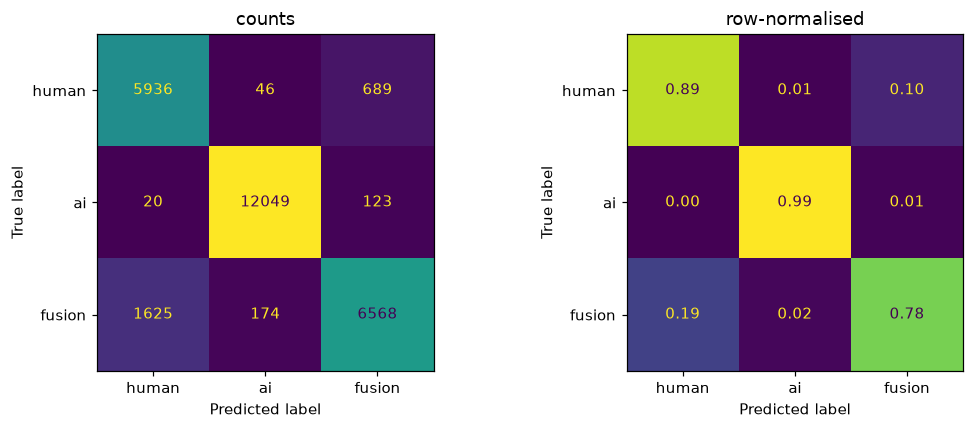

In [3]:
sub, val, test = fixed_sets()
yv = y_of(val)
pv = np.load(Path(PRED) / 'baseline_val.npy')
print(classification_report(yv, pv.argmax(1), target_names=LABELS, digits=4))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, norm, t in [(ax[0], None, 'counts'), (ax[1], 'true', 'row-normalised')]:
    ConfusionMatrixDisplay(confusion_matrix(yv, pv.argmax(1), normalize=norm), display_labels=LABELS).plot(
        ax=a, colorbar=False, values_format='.2f' if norm else 'd'); a.set_title(t)
plt.tight_layout(); plt.savefig(IMG / 'baseline_cm.png', bbox_inches='tight'); plt.show()

AI is almost solved (F1 ~0.985). Nearly all errors are human <-> fusion confusions: a fusion text is mostly copied human text, so bag-of-n-grams sees mostly human evidence.

## 3. Per-domain macro-F1

In [4]:
val['pred'] = np.array(LABELS)[pv.argmax(1)]
from sklearn.metrics import f1_score
dom = val.groupby('domain').apply(lambda d: pd.Series({'n': len(d), 'macro_f1': f1_score(d.label, d.pred, average='macro'),
                                                       'f1_fusion': f1_score(d.label == 'fusion', d.pred == 'fusion')}), include_groups=False)
dom.round(3)

,n,macro_f1,f1_fusion
domain,,,
arxiv_papers,1428.0,0.915,0.946
blog_authorship_corpus,4053.0,0.767,0.630
bundestag,5232.0,0.925,0.894
cnn_news,4427.0,0.872,0.777
euro_court_cases,2757.0,0.909,0.887
gutenberg,734.0,0.781,0.623
house_of_commons,3187.0,0.906,0.872
student_essays,5412.0,0.904,0.877


## 4. More data
The same pipeline fit on all non-validation folds (~245k texts) instead of 50k:

In [5]:
M[M.name.str.contains('tfidf_featword_modellr_C16_wng1-3')][['name', 'train', 'macro_f1', 'f1_human', 'f1_ai', 'f1_fusion', 'sec']]

,name,train,macro_f1,f1_human,f1_ai,f1_fusion,sec
8,tfidf_featword_modellr_C16_wng1-3,sub50k,0.8841,0.8330,0.9852,0.8342,258.0
12,tfidf_featword_modellr_C16_wng1-3_full,full,0.9030,0.8535,0.9913,0.8643,933.0
